In [1]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

# Grafici
from sklearn.manifold import TSNE

In [2]:
df = pd.read_csv("df.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

train_imputed_rf = pd.read_csv("train_imputed_rf.csv")
test_imputed_rf = pd.read_csv("test_imputed_rf.csv")

tt = np.concatenate([train_imputed, test_imputed], axis=0)

df_unito = pd.DataFrame(tt, columns=train_imputed.columns)

df_outliers = pd.read_csv('df_outliers.csv')

df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)


/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_41120/2411200864.py:1: DtypeWarning: Columns (53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("df.csv")


In [3]:
# come conviene gestire le stagioni? trasformarle in 1234 non ha senso in questo caso
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X=df_unito.values
y=np.array(df_unito['sii'])
X_standard=standard_scaler.fit_transform(X)
y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(X_standard, y, test_size=0.3, random_state=0)

  0%|          | 0/2 [00:00<?, ?it/s]

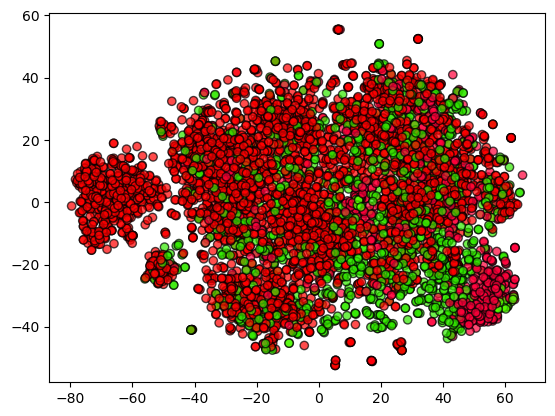

 50%|█████     | 1/2 [00:11<00:11, 11.06s/it]

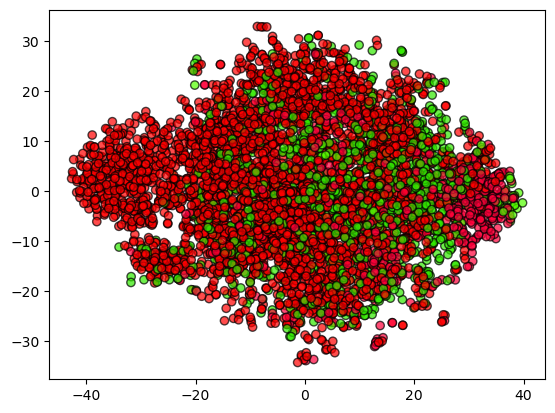

100%|██████████| 2/2 [00:30<00:00, 15.19s/it]


In [ ]:
comp=[2,3]
for x in tqdm(comp):
    tsne = TSNE(n_components=x)
    X_train_tsne = tsne.fit_transform(X_train)
    X_train_tsne.shape
    plt.scatter(X_train_tsne[:, 0], X_train_tsne[:, 1], c=y_train, cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
    plt.show()


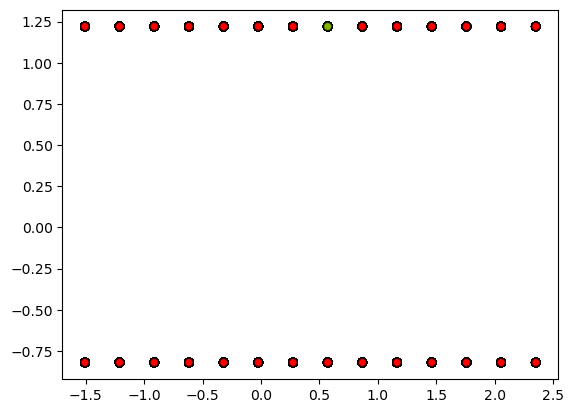

In [5]:
tsne = TSNE(n_components=2)
X_train_tsne = tsne.fit_transform(X_train)
X_train_tsne.shape
plt.scatter(X_standard[:, 0], X_standard[:, 1], c=df_outliers['colore'], cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
plt.show()


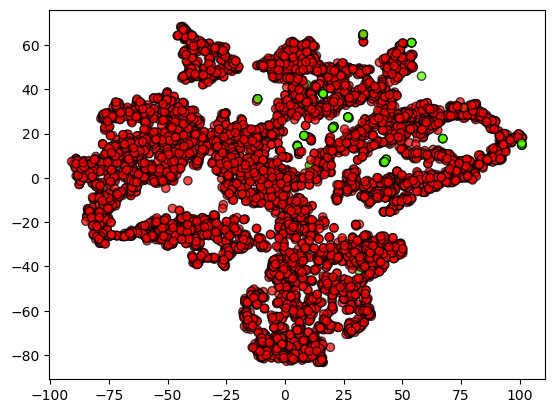

In [6]:
tsne = TSNE(n_components=2)
df_unito_tsne = tsne.fit_transform(df_unito)
df_unito.shape
plt.scatter(df_unito_tsne[:, 0], df_unito_tsne[:, 1], c=df_outliers['colore'], cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
plt.show()

In [7]:
#X_test_mds = mds.transform(X_test) # no transform

clf = DecisionTreeClassifier(min_samples_leaf=3, random_state=42)
clf.fit(X_train_tsne, y_train)

y_pred = clf.predict(X_train_tsne)

print('Accuracy %s' % accuracy_score(y_train, y_pred))
print('F1-score %s' % f1_score(y_train, y_pred, average=None))
print(classification_report(y_train, y_pred))

Accuracy 0.907092563970462
F1-score [0.94867429 0.80018674 0.82531646 0.74226804]
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      4033
           1       0.82      0.78      0.80      1098
           2       0.89      0.77      0.83       636
           3       0.88      0.64      0.74        56

    accuracy                           0.91      5823
   macro avg       0.88      0.79      0.83      5823
weighted avg       0.91      0.91      0.91      5823



  0%|          | 0/5 [00:00<?, ?it/s]

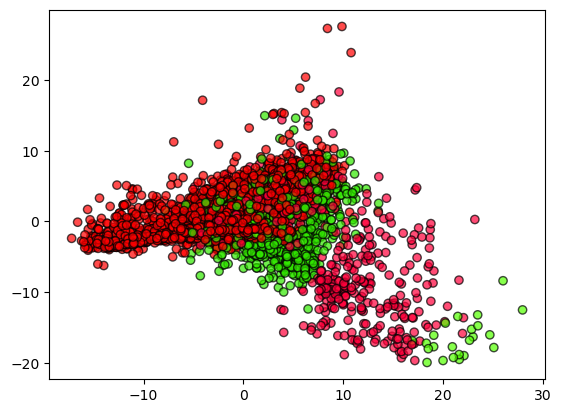

 20%|██        | 1/5 [00:27<01:51, 27.94s/it]

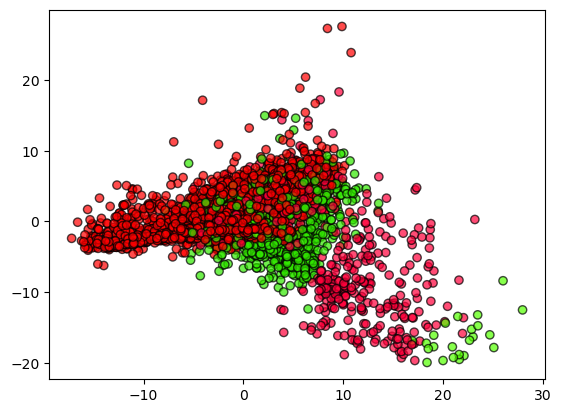

 40%|████      | 2/5 [00:56<01:24, 28.22s/it]

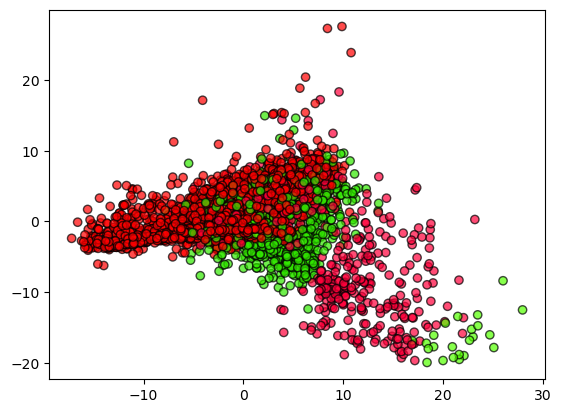

 60%|██████    | 3/5 [01:25<00:56, 28.48s/it]

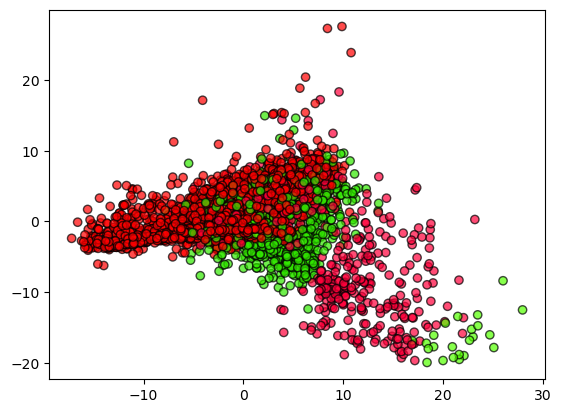

 80%|████████  | 4/5 [01:52<00:27, 27.87s/it]

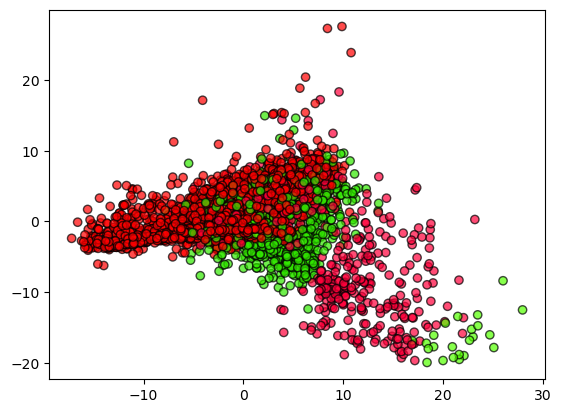

100%|██████████| 5/5 [02:18<00:00, 27.77s/it]


In [ ]:
from sklearn.manifold import Isomap
prova= [2,3,4,5,6]
for x in tqdm(prova):
    iso = Isomap(n_components=x, n_neighbors=76)
    X_train_iso = iso.fit_transform(X_train)
    X_train_iso.shape
    plt.scatter(X_train_iso[:, 0], X_train_iso[:, 1], c=df_outliers['colore'], cmap=plt.cm.prism, edgecolor='b', alpha=0.7)
    plt.show()

In [9]:
#X_test_mds = mds.transform(X_test) # no transform

clf = DecisionTreeClassifier(min_samples_leaf=3, random_state=42)
clf.fit(X_train_iso, y_train)

y_pred = clf.predict(X_train_iso)

print('Accuracy %s' % accuracy_score(y_train, y_pred))
print('F1-score %s' % f1_score(y_train, y_pred, average=None))
print(classification_report(y_train, y_pred))

Accuracy 0.9168813326464021
F1-score [0.95284513 0.84446478 0.81276963 0.74468085]
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      4033
           1       0.85      0.84      0.84      1098
           2       0.90      0.74      0.81       636
           3       0.92      0.62      0.74        56

    accuracy                           0.92      5823
   macro avg       0.90      0.79      0.84      5823
weighted avg       0.92      0.92      0.92      5823



In [15]:
iso = Isomap(n_components=2, n_neighbors=76)
df_unito_iso = iso.fit_transform(df_unito)
df_unito_iso.shape
plt.scatter(df_unito_iso[:, 0], df_unito_iso[:, 1], c=df_outliers['colore'], cmap=plt.cm.purples, alpha=0.7)
plt.show()

KeyboardInterrupt: 

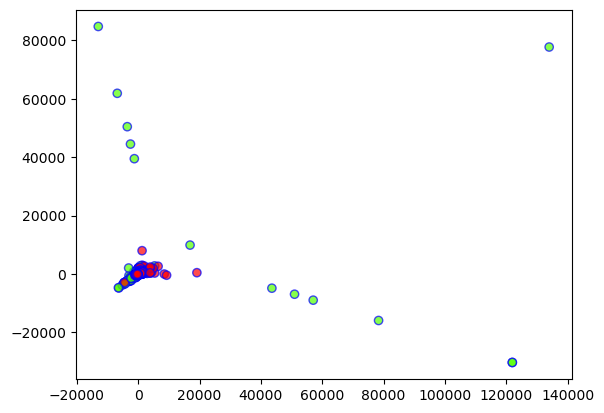

In [12]:
iso = Isomap(n_components=3, n_neighbors=76)
df_unito_iso = iso.fit_transform(df_unito)
df_unito_iso.shape
plt.scatter(df_unito_iso[:, 0], df_unito_iso[:, 1], c=df_outliers['colore'], cmap=plt.cm.prism, edgecolor='b', alpha=0.7)
plt.show()